# 01 · COCO val2017 data integrity check

**Purpose:** before any cleaning or modeling, confirm that what's on disk is complete and that the
annotations map to the images correctly.

| # | Check | Pass condition |
|---|---|---|
| 1 | Image file count | exactly 5,000 `.jpg` files, nothing else |
| 2 | Caption file structure | expected keys, 5,000 image records |
| 3 | Image ↔ annotation mapping | every file has a record and every record has a file; every caption points to a real image |
| 4 | Captions per image + caption quality | every image has ≥ 5 captions; no empty captions |
| 5 | Image files readable + match metadata | every file opens; on-disk size = JSON width/height |
| 6 | Instances file agrees with captions file | same 5,000 image IDs; 80 categories |
| 7 | Visual spot check | random images with their captions look correct (judged by eye) |

This notebook only **reads** data. It changes nothing on disk.

In [1]:
import json
import random
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Project root = parent of notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG_DIR = ROOT / "val2017"
CAP_PATH = ROOT / "annotations" / "captions_val2017.json"
INST_PATH = ROOT / "annotations" / "instances_val2017.json"

for p in (IMG_DIR, CAP_PATH, INST_PATH):
    print(f"{'OK ' if p.exists() else 'MISSING'}  {p.relative_to(ROOT)}")

results = {}  # check name -> (passed: bool, note: str)

Matplotlib is building the font cache; this may take a moment.


OK   val2017
OK   annotations/captions_val2017.json
OK   annotations/instances_val2017.json


## Check 1 · Image file count

In [2]:
all_files = sorted(p for p in IMG_DIR.iterdir() if not p.name.startswith("."))
jpgs = [p for p in all_files if p.suffix.lower() == ".jpg"]
other = [p.name for p in all_files if p.suffix.lower() != ".jpg"]

print(f"files in val2017/: {len(all_files):,}")
print(f".jpg files:        {len(jpgs):,}")
print(f"non-.jpg files:    {other[:10] if other else 'none'}")

results["1 file count"] = (len(jpgs) == 5000 and not other, f"{len(jpgs):,} jpgs, {len(other)} other")

files in val2017/: 5,000
.jpg files:        5,000
non-.jpg files:    none


## Check 2 · Caption file structure
COCO caption JSON has three main parts:
- `images`: one record per image (`id`, `file_name`, `width`, `height`, `coco_url`, …)
- `annotations`: one record per **caption** (`image_id`, `id`, `caption`)
- `info` / `licenses`: metadata

Images and captions are linked through `annotations[i]["image_id"] == images[j]["id"]`.

In [3]:
with open(CAP_PATH) as f:
    cap = json.load(f)

print("top-level keys:", list(cap.keys()))
print(f"image records:   {len(cap['images']):,}")
print(f"caption records: {len(cap['annotations']):,}")
print("\nexample image record:  ", cap["images"][0])
print("example caption record:", cap["annotations"][0])

results["2 caption structure"] = (
    {"images", "annotations"} <= cap.keys() and len(cap["images"]) == 5000,
    f"{len(cap['images']):,} images, {len(cap['annotations']):,} captions",
)

top-level keys: ['info', 'licenses', 'images', 'annotations']
image records:   5,000
caption records: 25,014

example image record:   {'license': 4, 'file_name': '000000397133.jpg', 'coco_url': 'http://images.cocodataset.org/val2017/000000397133.jpg', 'height': 427, 'width': 640, 'date_captured': '2013-11-14 17:02:52', 'flickr_url': 'http://farm7.staticflickr.com/6116/6255196340_da26cf2c9e_z.jpg', 'id': 397133}
example caption record: {'image_id': 179765, 'id': 38, 'caption': 'A black Honda motorcycle parked in front of a garage.'}


## Check 3 · Image ↔ annotation mapping
Checked in both directions, plus that IDs are unique and every caption points to a real image.

In [4]:
img_ids = [im["id"] for im in cap["images"]]
fname_by_id = {im["id"]: im["file_name"] for im in cap["images"]}

json_fnames = set(fname_by_id.values())
disk_fnames = {p.name for p in jpgs}

on_disk_not_in_json = disk_fnames - json_fnames
in_json_not_on_disk = json_fnames - disk_fnames
dup_ids = len(img_ids) - len(set(img_ids))
orphan_caps = [a for a in cap["annotations"] if a["image_id"] not in fname_by_id]

# COCO filenames are the zero-padded image id; confirm that convention holds
name_id_mismatch = [i for i, fn in fname_by_id.items() if fn != f"{i:012d}.jpg"]

print(f"files on disk with no JSON record: {len(on_disk_not_in_json)}")
print(f"JSON records with no file on disk: {len(in_json_not_on_disk)}")
print(f"duplicate image IDs:               {dup_ids}")
print(f"captions pointing to unknown image:{len(orphan_caps)}")
print(f"file_name != zero-padded id:       {len(name_id_mismatch)}")

ok = not (on_disk_not_in_json or in_json_not_on_disk or dup_ids or orphan_caps or name_id_mismatch)
results["3 mapping"] = (ok, "1:1 files↔records, no orphans" if ok else "see output above")

files on disk with no JSON record: 0
JSON records with no file on disk: 0
duplicate image IDs:               0
captions pointing to unknown image:0
file_name != zero-padded id:       0


## Check 4 · Captions per image + caption quality

In [5]:
caps_by_img = {}
for a in cap["annotations"]:
    caps_by_img.setdefault(a["image_id"], []).append(a["caption"].strip())

per_img = Counter(len(caps_by_img.get(i, [])) for i in img_ids)
print("captions per image -> number of images:", dict(sorted(per_img.items())))

no_caps = [i for i in img_ids if i not in caps_by_img]
empty = [(i, c) for i, cs in caps_by_img.items() for c in cs if not c]
dup_within = {i: cs for i, cs in caps_by_img.items() if len(set(c.lower() for c in cs)) < len(cs)}

lens = np.array([len(c.split()) for cs in caps_by_img.values() for c in cs])
print(f"images with zero captions:  {len(no_caps)}")
print(f"empty captions:             {len(empty)}")
print(f"images w/ duplicate caption:{len(dup_within)}")
print(f"caption length (words): min {lens.min()}, median {np.median(lens):.0f}, "
      f"mean {lens.mean():.1f}, max {lens.max()}")

all_caps = [(i, c) for i, cs in caps_by_img.items() for c in cs]
all_caps.sort(key=lambda t: len(t[1].split()))
print("\nshortest 3:", [c for _, c in all_caps[:3]])
print("longest 1: ", all_caps[-1][1])

results["4 captions"] = (
    min(per_img) >= 5 and not no_caps and not empty,
    f"{min(per_img)}–{max(per_img)} per image, {len(empty)} empty",
)

captions per image -> number of images: {5: 4987, 6: 12, 7: 1}
images with zero captions:  0
empty captions:             0
images w/ duplicate caption:8
caption length (words): min 7, median 10, mean 10.4, max 50

shortest 3: ['An airplane just landed on the runway', 'Cat messing around in the white bathtub.', 'many vehicles stopped on a city street']
longest 1:  A large square concrete wall, which shows people over the rim, has inside of it a pinkish cloud of dust and a fallen bull as well as two horses, the closest of which is trotting forward with a man in western gear , who is looking back at the bull.


## Check 5 · Image files readable + match metadata
`verify()` reads each file fully enough to catch truncated or corrupted JPEGs. Size and color mode
come from the header. Grayscale (`L`) images are **not** an error here. They're recorded so the
cleaning step can decide what to do with them.

In [6]:
meta = {im["file_name"]: (im["width"], im["height"]) for im in cap["images"]}
corrupt, size_mismatch, modes, sizes = [], [], Counter(), []

for p in jpgs:
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:          # reopen: verify() leaves the object unusable
            w, h = im.size
            modes[im.mode] += 1
    except Exception as e:
        corrupt.append((p.name, repr(e)))
        continue
    sizes.append((w, h))
    if meta.get(p.name) != (w, h):
        size_mismatch.append((p.name, (w, h), meta.get(p.name)))

sizes = np.array(sizes)
ar = sizes[:, 0] / sizes[:, 1]
print(f"unreadable/corrupt files: {len(corrupt)}  {corrupt[:3]}")
print(f"size != JSON metadata:    {len(size_mismatch)}  {size_mismatch[:3]}")
print(f"color modes:              {dict(modes)}")
print(f"width  range: {sizes[:,0].min()}–{sizes[:,0].max()}   height range: {sizes[:,1].min()}–{sizes[:,1].max()}")
print(f"shorter side < 512 px:    {(sizes.min(axis=1) < 512).sum():,} images")
print(f"aspect ratio (w/h):       min {ar.min():.2f}, median {np.median(ar):.2f}, max {ar.max():.2f}")

results["5 files readable"] = (not corrupt and not size_mismatch,
                               f"{len(corrupt)} corrupt, {len(size_mismatch)} size mismatches; modes {dict(modes)}")

unreadable/corrupt files: 0  []
size != JSON metadata:    0  []
color modes:              {'RGB': 4990, 'L': 10}
width  range: 200–640   height range: 145–640
shorter side < 512 px:    4,657 images
aspect ratio (w/h):       min 0.38, median 1.33, max 4.03


## Check 6 · Instances file agrees with captions file
The instances file holds the object categories (useful later for describing the data and for bias analysis).
Some COCO images contain none of the 80 categories, so a few images with zero object annotations is expected.

In [7]:
with open(INST_PATH) as f:
    inst = json.load(f)

inst_ids = {im["id"] for im in inst["images"]}
cats = {c["id"]: c["name"] for c in inst["categories"]}
imgs_with_objs = {a["image_id"] for a in inst["annotations"]}

print(f"instances image records: {len(inst_ids):,}")
print(f"same ID set as captions: {inst_ids == set(img_ids)}")
print(f"categories:              {len(cats)}")
print(f"images with ≥1 object:   {len(imgs_with_objs):,}  (zero objects: {len(inst_ids - imgs_with_objs)})")

imgs_per_cat = Counter()
for cid, iid in {(a["category_id"], a["image_id"]) for a in inst["annotations"]}:
    imgs_per_cat[cats[cid]] += 1
print("\nmost common (images containing):  ", imgs_per_cat.most_common(5))
print("least common (images containing): ", imgs_per_cat.most_common()[-5:])

results["6 instances agree"] = (inst_ids == set(img_ids) and len(cats) == 80,
                                f"{len(cats)} categories, ID sets match: {inst_ids == set(img_ids)}")

instances image records: 5,000
same ID set as captions: True
categories:              80
images with ≥1 object:   4,952  (zero objects: 48)

most common (images containing):   [('person', 2693), ('chair', 580), ('car', 535), ('dining table', 501), ('cup', 390)]
least common (images containing):  [('parking meter', 37), ('toothbrush', 34), ('scissors', 28), ('hair drier', 9), ('toaster', 8)]


## Check 7 · Visual spot check
Random images with their first caption. **Your call:** do the captions describe the pictures?
A systematic mismatch here would mean the ID mapping is wrong even if checks 1–6 passed.

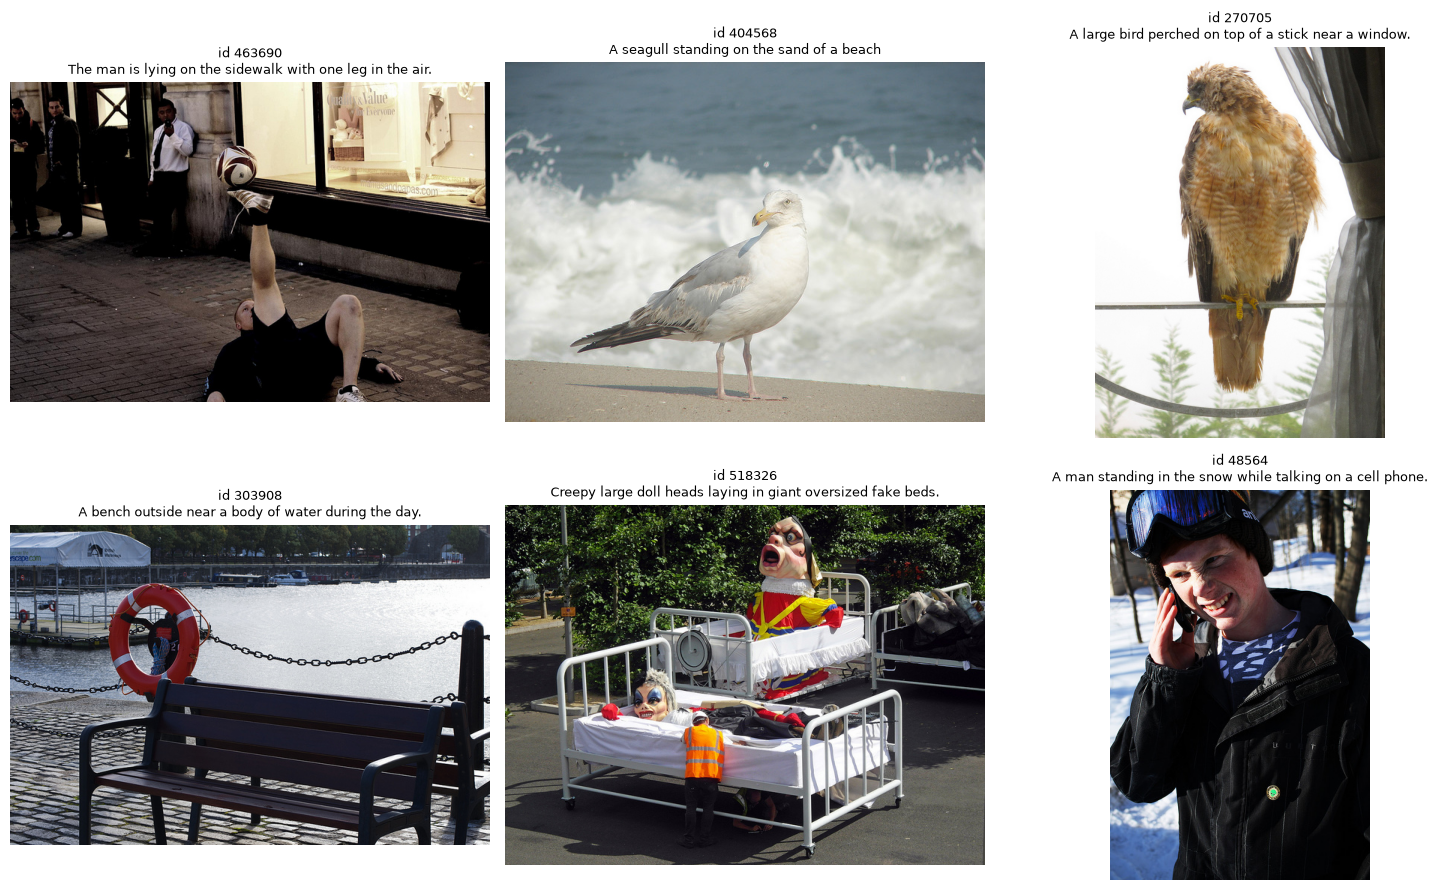

In [8]:
rng = random.Random(7615)  # fixed seed -> same sample every run
sample = rng.sample(img_ids, 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, iid in zip(axes.flat, sample):
    ax.imshow(Image.open(IMG_DIR / fname_by_id[iid]).convert("RGB"))
    ax.set_title(f"id {iid}\n{caps_by_img[iid][0]}", fontsize=9, wrap=True)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Summary

In [9]:
width = max(len(k) for k in results)
for name, (passed, note) in results.items():
    print(f"{'PASS' if passed else 'FAIL'}  {name:<{width}}  {note}")
print("\nAll automated checks passed." if all(p for p, _ in results.values())
      else "\nSome checks FAILED. Look at the output above before continuing.")

PASS  1 file count         5,000 jpgs, 0 other
PASS  2 caption structure  5,000 images, 25,014 captions
PASS  3 mapping            1:1 files↔records, no orphans
PASS  4 captions           5–7 per image, 0 empty
PASS  5 files readable     0 corrupt, 0 size mismatches; modes {'RGB': 4990, 'L': 10}
PASS  6 instances agree    80 categories, ID sets match: True

All automated checks passed.
